In [7]:
import os, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.manifold import TSNE

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

DATA_DIR = 'cmapss_data'
os.makedirs(DATA_DIR, exist_ok=True)

# Download each file directly from a GitHub mirror (no zip needed)
BASE_URL = 'https://raw.githubusercontent.com/hankroark/Turbofan-Engine-Degradation/master/CMAPSSData/'
FILES = ['train_FD001.txt', 'test_FD001.txt', 'RUL_FD001.txt']

for fname in FILES:
    out_path = os.path.join(DATA_DIR, fname)
    if os.path.exists(out_path):
        print(f'  {fname} already exists, skipping.')
        continue
    url = BASE_URL + fname
    print(f'  Downloading {fname} ...')
    try:
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=30) as resp:
            data = resp.read()
        with open(out_path, 'wb') as f:
            f.write(data)
        print(f'    → saved ({len(data)//1024} KB)')
    except Exception as e:
        print(f'    FAILED: {e}')
        print(f'    Manually download {fname} from:')
        print(f'    https://github.com/hankroark/Turbofan-Engine-Degradation/tree/master/CMAPSSData')
        print(f'    and place it in: {os.path.abspath(DATA_DIR)}/')

# Verify
missing = [f for f in FILES if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    raise FileNotFoundError(f'Missing files: {missing}. See download instructions above.')

# Load
col_names = ['engine', 'cycle', 'os1', 'os2', 'os3'] + [f's{i}' for i in range(1, 22)]
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train_FD001.txt'), sep=r'\s+', header=None, names=col_names)
test_df  = pd.read_csv(os.path.join(DATA_DIR, 'test_FD001.txt'),  sep=r'\s+', header=None, names=col_names)
rul_df   = pd.read_csv(os.path.join(DATA_DIR, 'RUL_FD001.txt'),   sep=r'\s+', header=None, names=['rul_final'])

print(f'\ntrain_df: {train_df.shape}  |  test_df: {test_df.shape}  |  rul_df: {rul_df.shape}')
print(f'Train engines: {train_df["engine"].nunique()}  |  Test engines: {test_df["engine"].nunique()}')


Device: cpu
  train_FD001.txt already exists, skipping.
  test_FD001.txt already exists, skipping.
  RUL_FD001.txt already exists, skipping.

train_df: (20631, 26)  |  test_df: (13096, 26)  |  rul_df: (100, 1)
Train engines: 100  |  Test engines: 100


In [8]:
MAX_RUL = 125
WINDOW  = 30
STRIDE_TRAIN = 1
STRIDE_TEST  = 5

sensor_cols = [f's{i}' for i in range(1, 22)]

# --- Drop near-constant sensors (std < 0.01 on training data) ---
sensor_stds  = train_df[sensor_cols].std()
drop_sensors = sensor_stds[sensor_stds < 0.01].index.tolist()
keep_sensors = [c for c in sensor_cols if c not in drop_sensors]
print(f'Dropped ({len(drop_sensors)}): {drop_sensors}')
print(f'Kept    ({len(keep_sensors)}): {keep_sensors}')
N_SENSORS = len(keep_sensors)

# --- Min-Max Normalization ---
scaler = MinMaxScaler()
train_df[keep_sensors] = scaler.fit_transform(train_df[keep_sensors])
test_df[keep_sensors]  = scaler.transform(test_df[keep_sensors]).clip(0.0, 1.0)

# --- RUL for TRAIN (vectorized) ---
max_cycle_train = train_df.groupby('engine')['cycle'].max().rename('max_cycle')
train_df = train_df.join(max_cycle_train, on='engine')
train_df['rul'] = (train_df['max_cycle'] - train_df['cycle']).clip(upper=MAX_RUL)
train_df.drop(columns=['max_cycle'], inplace=True)

# --- RUL for TEST (vectorized) ---
# rul_df row i → engine i+1 (1-indexed), value = RUL at last observed cycle
max_cycle_test = test_df.groupby('engine')['cycle'].max().rename('max_cycle')
test_df = test_df.join(max_cycle_test, on='engine')

# Map engine id → rul_final value
rul_finals = rul_df['rul_final'].values                         # 0-indexed
test_df['rul_final'] = rul_finals[test_df['engine'].astype(int) - 1]
test_df['rul'] = (test_df['rul_final'] + (test_df['max_cycle'] - test_df['cycle'])).clip(upper=MAX_RUL)
test_df.drop(columns=['max_cycle', 'rul_final'], inplace=True)

# --- Sliding Window Sequences ---
def make_sequences(df, window, stride):
    X_list, y_list = [], []
    for eng, grp in df.groupby('engine'):
        sensors = grp[keep_sensors].values.astype(np.float32)   # (T, N_S)
        rul_arr = grp['rul'].values.astype(np.float32)           # (T,)
        T = len(sensors)
        if T < window:
            continue
        for start in range(0, T - window + 1, stride):
            X_list.append(sensors[start : start + window])
            y_list.append(rul_arr[start : start + window])
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)

X_train, y_train = make_sequences(train_df, WINDOW, STRIDE_TRAIN)
X_test,  y_test  = make_sequences(test_df,  WINDOW, STRIDE_TEST)

print(f'\nN_SENSORS         : {N_SENSORS}')
print(f'Train sequences   : {X_train.shape}')
print(f'Test  sequences   : {X_test.shape}')
print(f'RUL range (train) : {y_train.min():.0f} – {y_train.max():.0f}')

train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
    batch_size=256, shuffle=True, drop_last=True
)
test_loader = DataLoader(
    TensorDataset(torch.tensor(X_test), torch.tensor(y_test)),
    batch_size=256, shuffle=False
)


Dropped (7): ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
Kept    (14): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']

N_SENSORS         : 14
Train sequences   : (17731, 30, 14)
Test  sequences   : (2079, 30, 14)
RUL range (train) : 0 – 125


In [9]:
# Cell 2 — World Model Architecture

class MLP(nn.Module):
    def __init__(self, in_dim, hidden_dims, out_dim, dropout=0.3):
        super().__init__()
        layers = []
        dims = [in_dim] + list(hidden_dims) + [out_dim]
        for i in range(len(dims) - 1):
            layers.append(nn.Linear(dims[i], dims[i + 1]))
            if i < len(dims) - 2:  # no activation/dropout on last layer
                layers.append(nn.ELU())
                layers.append(nn.Dropout(dropout))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class WorldModel(nn.Module):
    def __init__(self, n_sensors, latent_dim=16, hidden_dim=64, dropout=0.3):
        super().__init__()
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.n_sensors  = n_sensors

        # Encoder: sensor space → latent space
        self.encoder = MLP(n_sensors, [64, 32], latent_dim, dropout=dropout)

        # LSTM: processes latent sequence, outputs hidden state sequence
        self.lstm = nn.LSTM(
            input_size=latent_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        # Dynamics head: predict next latent from current hidden state
        self.dynamics_head = MLP(hidden_dim, [64], latent_dim, dropout=dropout)

        # Decoder: latent space → sensor space
        self.decoder = MLP(latent_dim, [32, 64], n_sensors, dropout=dropout)

        # RUL head: hidden state → scalar RUL prediction
        self.rul_head = MLP(hidden_dim, [32], 1, dropout=dropout)

    def encode(self, x):
        """x: (B, T, N_S) → (B, T, latent_dim)"""
        B, T, N = x.shape
        z = self.encoder(x.reshape(B * T, N))
        return z.reshape(B, T, self.latent_dim)

    def decode(self, z):
        """z: (B, T, latent_dim) → (B, T, N_S)"""
        B, T, L = z.shape
        out = self.decoder(z.reshape(B * T, L))
        return out.reshape(B, T, self.n_sensors)

    def forward(self, x, hidden=None):
        """
        x: (B, T, N_S)
        Returns:
            recon       (B, T, N_S)   — reconstructed sensors
            z           (B, T, L)     — latent encodings
            z_next_pred (B, T-1, L)   — predicted next latent at each step
            rul_pred    (B, T, 1)     — RUL prediction at each step
            hidden      tuple         — LSTM hidden state
        """
        z = self.encode(x)                           # (B, T, L)
        h, hidden = self.lstm(z, hidden)             # h: (B, T, hidden_dim)
        z_next_pred = self.dynamics_head(h[:, :-1])  # (B, T-1, L)
        recon    = self.decode(z)                    # (B, T, N_S)
        rul_pred = self.rul_head(h)                  # (B, T, 1)
        return recon, z, z_next_pred, rul_pred, hidden

    def mc_rollout(self, seed_x, n_steps=50, n_samples=30):
        """
        seed_x: (WINDOW, N_S) numpy array — last known sensor readings
        Returns:
            sensor_traj (n_steps, N_S)
            rul_traj    (n_steps,)
            rul_std     (n_steps,)
        """
        self.train()  # keep dropout active for MC Dropout

        all_sensor_trajs = []
        all_rul_trajs    = []

        seed_tensor = torch.tensor(seed_x, dtype=torch.float32).unsqueeze(0).to(device)
        # seed_tensor: (1, WINDOW, N_S)

        for _ in range(n_samples):
            with torch.no_grad():
                # Warm-up: encode seed window to get initial hidden state
                z_seed = self.encode(seed_tensor)          # (1, WINDOW, L)
                h_all, hidden = self.lstm(z_seed)          # h_all: (1, WINDOW, hidden_dim)

                sensor_traj = []
                rul_traj    = []

                # Start imagining from the last latent of the seed
                z_curr = self.dynamics_head(h_all[:, -1:])  # (1, 1, L)

                for step in range(n_steps):
                    # Decode current latent to sensor space
                    sensor_t = self.decode(z_curr).squeeze(0).squeeze(0)  # (N_S,)
                    sensor_traj.append(sensor_t.cpu().numpy())

                    # LSTM step on current latent
                    h_t, hidden = self.lstm(z_curr, hidden)  # h_t: (1, 1, hidden_dim)

                    # Predict RUL
                    rul_t = self.rul_head(h_t).squeeze().item()
                    rul_traj.append(max(0.0, rul_t))

                    # Predict next latent
                    z_curr = self.dynamics_head(h_t)  # (1, 1, L)

                all_sensor_trajs.append(np.array(sensor_traj))
                all_rul_trajs.append(np.array(rul_traj))

        sensor_arr = np.stack(all_sensor_trajs)   # (n_samples, n_steps, N_S)
        rul_arr    = np.stack(all_rul_trajs)       # (n_samples, n_steps)

        sensor_traj_mean = sensor_arr.mean(axis=0)  # (n_steps, N_S)
        rul_traj_mean    = rul_arr.mean(axis=0)     # (n_steps,)
        rul_std          = rul_arr.std(axis=0)      # (n_steps,)

        return sensor_traj_mean, rul_traj_mean, rul_std


# Instantiate model
model = WorldModel(
    n_sensors=N_SENSORS,
    latent_dim=16,
    hidden_dim=64,
    dropout=0.3
).to(device)

print(model)
print(f'\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}')

WorldModel(
  (encoder): MLP(
    (net): Sequential(
      (0): Linear(in_features=14, out_features=64, bias=True)
      (1): ELU(alpha=1.0)
      (2): Dropout(p=0.3, inplace=False)
      (3): Linear(in_features=64, out_features=32, bias=True)
      (4): ELU(alpha=1.0)
      (5): Dropout(p=0.3, inplace=False)
      (6): Linear(in_features=32, out_features=16, bias=True)
    )
  )
  (lstm): LSTM(16, 64, batch_first=True)
  (dynamics_head): MLP(
    (net): Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): ELU(alpha=1.0)
      (2): Dropout(p=0.3, inplace=False)
      (3): Linear(in_features=64, out_features=16, bias=True)
    )
  )
  (decoder): MLP(
    (net): Sequential(
      (0): Linear(in_features=16, out_features=32, bias=True)
      (1): ELU(alpha=1.0)
      (2): Dropout(p=0.3, inplace=False)
      (3): Linear(in_features=32, out_features=64, bias=True)
      (4): ELU(alpha=1.0)
      (5): Dropout(p=0.3, inplace=False)
      (6): Linear(in_features

Epoch   1/100 | Total=0.6418 | Recon=0.0500 | Dynamics=0.0335 | RUL=0.575093
Epoch  20/100 | Total=0.0951 | Recon=0.0061 | Dynamics=0.1060 | RUL=0.035982
Epoch  40/100 | Total=0.0795 | Recon=0.0052 | Dynamics=0.0852 | RUL=0.031690
Epoch  60/100 | Total=0.0731 | Recon=0.0049 | Dynamics=0.0775 | RUL=0.029522
Epoch  80/100 | Total=0.0707 | Recon=0.0048 | Dynamics=0.0746 | RUL=0.028649
Epoch 100/100 | Total=0.0704 | Recon=0.0047 | Dynamics=0.0743 | RUL=0.028452


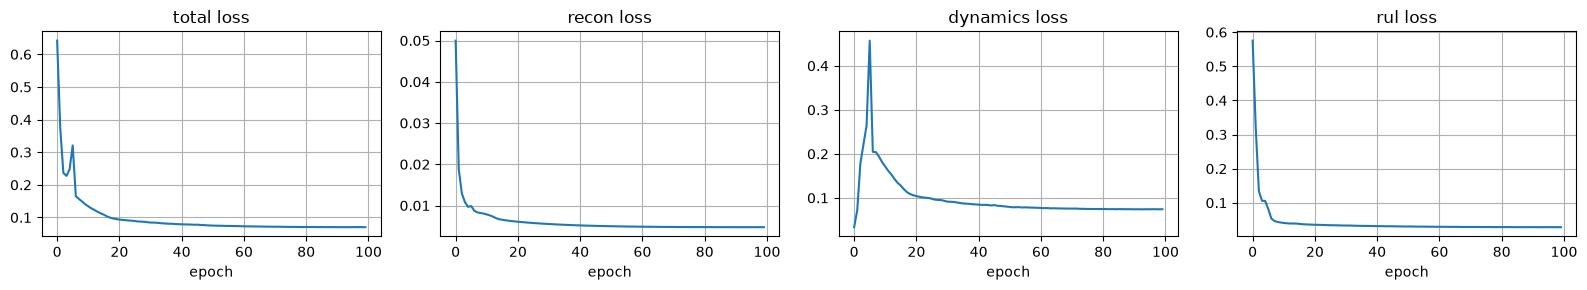

Training complete.


In [10]:
# Cell 3 — Training

EPOCHS = 100
LR     = 1e-3

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

mse = nn.MSELoss()

history = {'total': [], 'recon': [], 'dynamics': [], 'rul': []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_total    = 0.0
    epoch_recon    = 0.0
    epoch_dynamics = 0.0
    epoch_rul      = 0.0
    n_batches = 0

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)   # (B, WINDOW, N_S)
        y_batch = y_batch.to(device)   # (B, WINDOW)

        optimizer.zero_grad()

        recon, z, z_next_pred, rul_pred, _ = model(x_batch)
        # recon:       (B, WINDOW, N_S)
        # z:           (B, WINDOW, L)
        # z_next_pred: (B, WINDOW-1, L)
        # rul_pred:    (B, WINDOW, 1)

        # Reconstruction loss
        L_recon = mse(recon, x_batch)

        # Dynamics loss: predict next latent from current hidden state
        L_dynamics = mse(z_next_pred, z[:, 1:].detach())

        # RUL loss (normalized by MAX_RUL^2 for scale)
        L_rul = mse(rul_pred.squeeze(-1), y_batch) / (MAX_RUL ** 2)

        loss = L_recon + 0.5 * L_dynamics + L_rul
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        epoch_total    += loss.item()
        epoch_recon    += L_recon.item()
        epoch_dynamics += L_dynamics.item()
        epoch_rul      += L_rul.item()
        n_batches      += 1

    scheduler.step()

    avg_total    = epoch_total    / n_batches
    avg_recon    = epoch_recon    / n_batches
    avg_dynamics = epoch_dynamics / n_batches
    avg_rul      = epoch_rul      / n_batches

    history['total'].append(avg_total)
    history['recon'].append(avg_recon)
    history['dynamics'].append(avg_dynamics)
    history['rul'].append(avg_rul)

    if epoch % 20 == 0 or epoch == 1:
        print(f'Epoch {epoch:3d}/{EPOCHS} | '
              f'Total={avg_total:.4f} | '
              f'Recon={avg_recon:.4f} | '
              f'Dynamics={avg_dynamics:.4f} | '
              f'RUL={avg_rul:.6f}')

# Plot training curves
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, key in zip(axes, ['total', 'recon', 'dynamics', 'rul']):
    ax.plot(history[key])
    ax.set_title(f'{key} loss')
    ax.set_xlabel('epoch')
    ax.grid(True)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=100, bbox_inches='tight')
plt.show()
print('Training complete.')

RMSE on test RUL      : 13.60 cycles
NASA Asymmetric Score : 254.11  (lower is better)


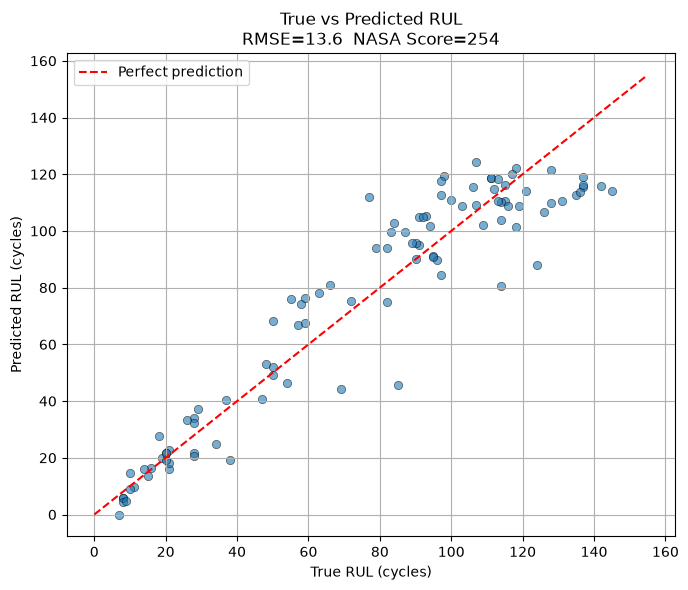

In [11]:
# Cell 4 — Evaluation (Test Set)

model.eval()

# For each test engine, take the LAST WINDOW cycles and predict RUL at final timestep.
# Ground truth: rul_df.iloc[eng-1]['rul_final']

test_engines = sorted(test_df['engine'].unique())
pred_ruls  = []
true_ruls  = []

with torch.no_grad():
    for eng in test_engines:
        grp = test_df[test_df['engine'] == eng]
        sensors = grp[keep_sensors].values.astype(np.float32)  # (T, N_S)
        T = len(sensors)

        if T >= WINDOW:
            window_data = sensors[-WINDOW:]   # last WINDOW cycles
        else:
            # Pad with first row if engine has fewer cycles than WINDOW
            pad = np.repeat(sensors[:1], WINDOW - T, axis=0)
            window_data = np.vstack([pad, sensors])

        x_t = torch.tensor(window_data, dtype=torch.float32).unsqueeze(0).to(device)
        # x_t: (1, WINDOW, N_S)

        _, _, _, rul_pred_seq, _ = model(x_t)
        # rul_pred_seq: (1, WINDOW, 1)
        pred_rul = rul_pred_seq[0, -1, 0].item()   # RUL at last timestep
        pred_rul = max(0.0, pred_rul)               # clamp to non-negative

        true_rul = float(rul_df.iloc[eng - 1]['rul_final'])

        pred_ruls.append(pred_rul)
        true_ruls.append(true_rul)

pred_ruls = np.array(pred_ruls)
true_ruls = np.array(true_ruls)

# RMSE
rmse = np.sqrt(np.mean((pred_ruls - true_ruls) ** 2))

# NASA Asymmetric Score
# d = pred - true; penalizes late predictions more heavily
d = pred_ruls - true_ruls
nasa_score = np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))

print(f'RMSE on test RUL      : {rmse:.2f} cycles')
print(f'NASA Asymmetric Score : {nasa_score:.2f}  (lower is better)')

# Scatter plot
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(true_ruls, pred_ruls, alpha=0.6, edgecolors='k', linewidths=0.5)
max_val = max(true_ruls.max(), pred_ruls.max()) + 10
ax.plot([0, max_val], [0, max_val], 'r--', label='Perfect prediction')
ax.set_xlabel('True RUL (cycles)')
ax.set_ylabel('Predicted RUL (cycles)')
ax.set_title(f'True vs Predicted RUL\nRMSE={rmse:.1f}  NASA Score={nasa_score:.0f}')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig('rul_scatter.png', dpi=100, bbox_inches='tight')
plt.show()

Selected engines (engine_id, true_RUL): [(np.int64(60), np.float64(100.0)), (np.int64(17), np.float64(50.0)), (np.int64(24), np.float64(20.0))]


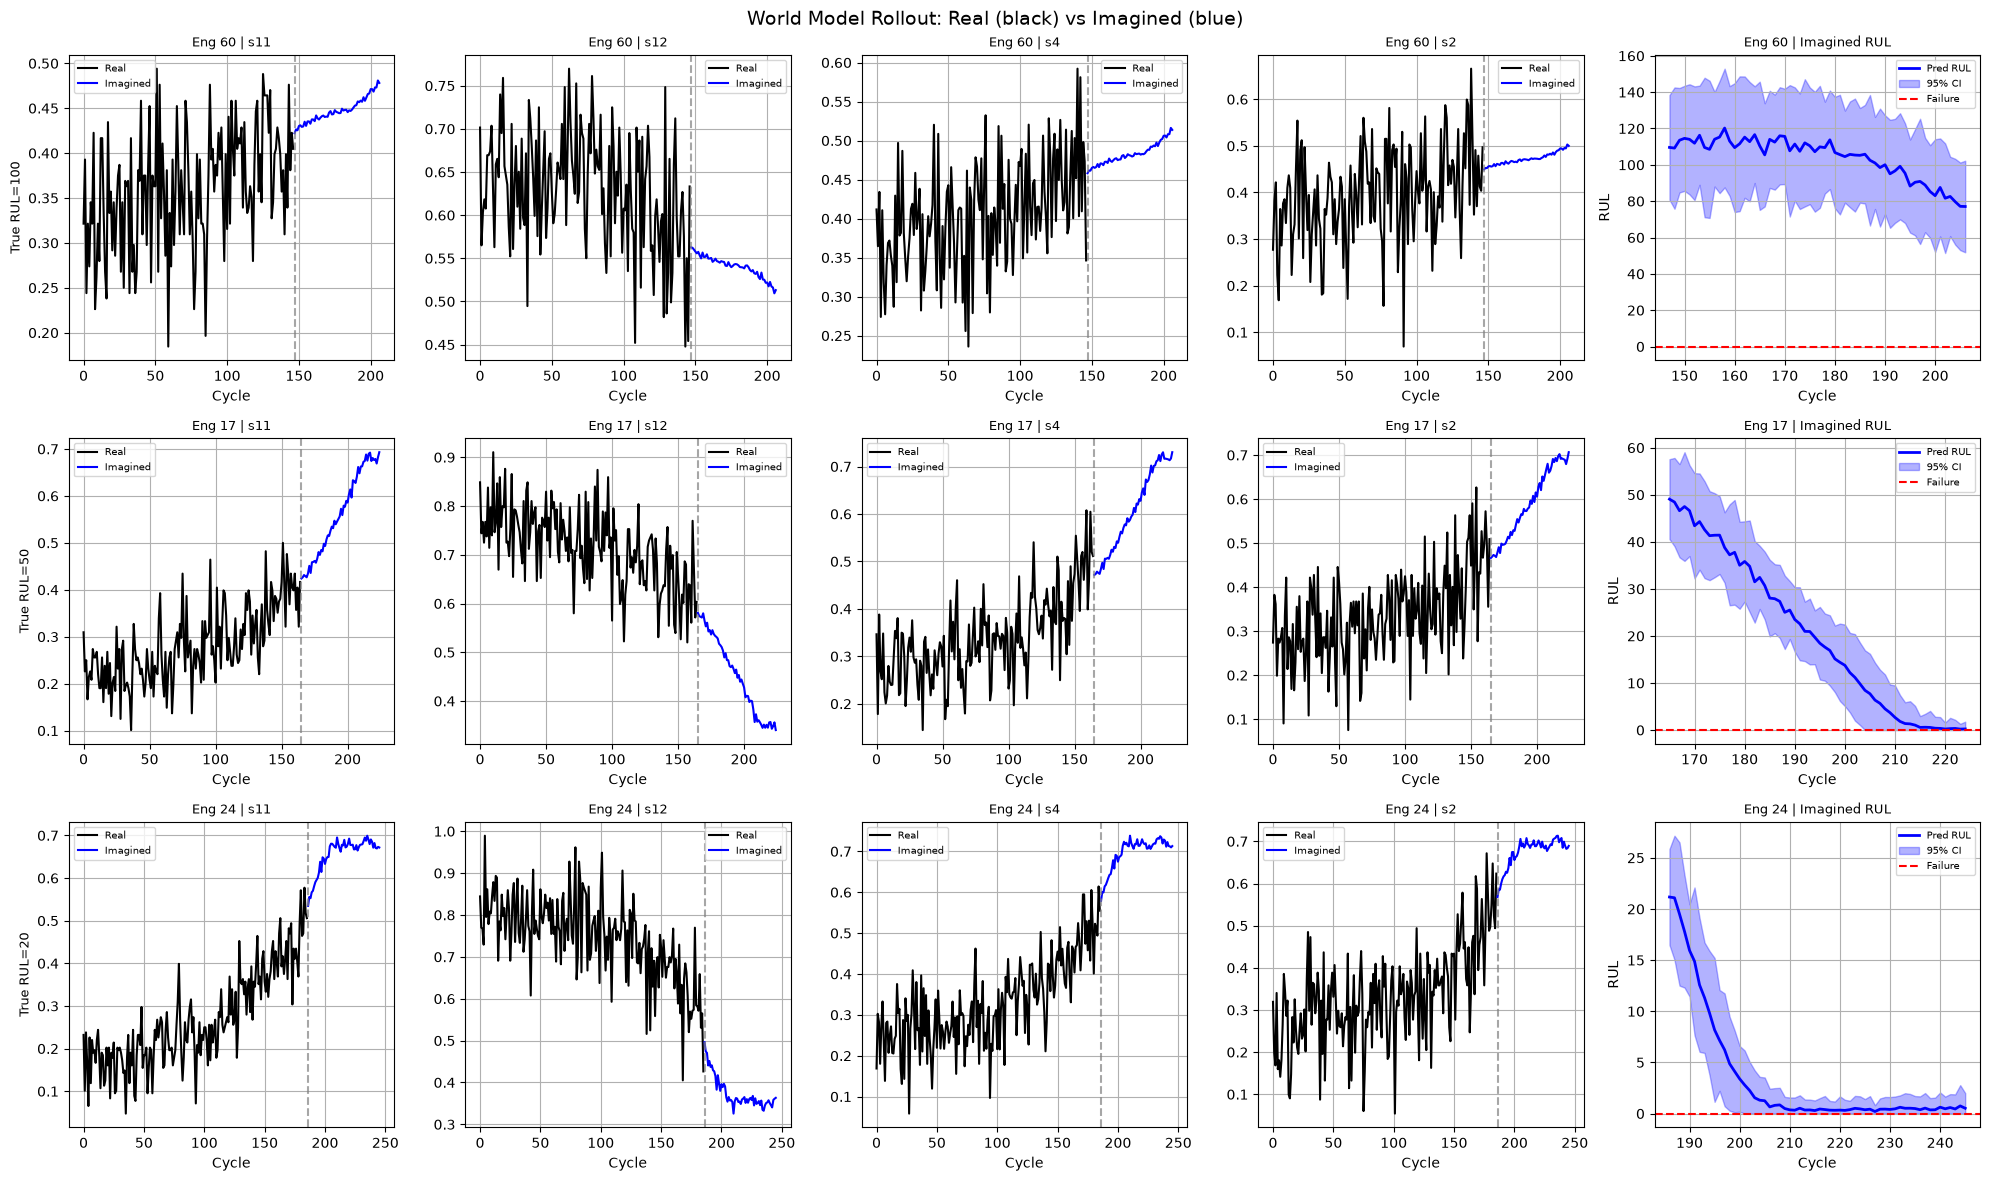

In [12]:
# Cell 5 — World Model Rollout (Imagination)

N_ROLLOUT_STEPS = 60
N_MC_SAMPLES    = 30

# Pick 3 test engines: high RUL (~100), mid (~50), low (~20)
# true_ruls and test_engines are from Cell 4
test_rul_pairs = list(zip(test_engines, true_ruls))
targets = [100, 50, 20]
selected_engines = []
for target in targets:
    eng, rul = min(test_rul_pairs, key=lambda er: abs(er[1] - target))
    selected_engines.append((eng, rul))
    test_rul_pairs = [(e, r) for (e, r) in test_rul_pairs if e != eng]  # no repeats

print('Selected engines (engine_id, true_RUL):', selected_engines)

# Choose 3 most informative sensors (highest variance in training data)
train_sensor_means = train_df[keep_sensors].std().nlargest(4).index.tolist()
plot_sensors = train_sensor_means[:4]
plot_idx = [keep_sensors.index(s) for s in plot_sensors]

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
fig.suptitle('World Model Rollout: Real (black) vs Imagined (blue)', fontsize=14)

for row_idx, (eng, true_rul) in enumerate(selected_engines):
    grp = test_df[test_df['engine'] == eng]
    sensors = grp[keep_sensors].values.astype(np.float32)
    T = len(sensors)

    # Seed window
    if T >= WINDOW:
        seed = sensors[-WINDOW:]
        real_hist = sensors  # all available real data
    else:
        pad = np.repeat(sensors[:1], WINDOW - T, axis=0)
        seed = np.vstack([pad, sensors])
        real_hist = sensors

    # MC Rollout
    sensor_traj, rul_traj, rul_std = model.mc_rollout(
        seed, n_steps=N_ROLLOUT_STEPS, n_samples=N_MC_SAMPLES
    )
    model.eval()  # restore eval mode after MC rollout

    # Time axes
    real_t     = np.arange(len(real_hist))
    imagined_t = np.arange(len(real_hist), len(real_hist) + N_ROLLOUT_STEPS)

    for col_idx, (s_idx, s_name) in enumerate(zip(plot_idx, plot_sensors)):
        ax = axes[row_idx, col_idx]
        # Real trajectory
        ax.plot(real_t, real_hist[:, s_idx], 'k-', linewidth=1.5, label='Real')
        # Imagined trajectory with 95% CI (sensor-level: use std across MC samples)
        ax.plot(imagined_t, sensor_traj[:, s_idx], 'b-', linewidth=1.5, label='Imagined')
        # Approximate sensor CI using rul_std as proxy (not per-sensor std here)
        ax.axvline(x=len(real_hist), color='gray', linestyle='--', alpha=0.7)
        ax.set_title(f'Eng {eng} | {s_name}', fontsize=9)
        ax.set_xlabel('Cycle')
        if col_idx == 0:
            ax.set_ylabel(f'True RUL={true_rul:.0f}', fontsize=9)
        ax.legend(fontsize=7)
        ax.grid(True)

    # RUL prediction plot in 5th column
    ax = axes[row_idx, 4]
    ax.plot(imagined_t, rul_traj, 'b-', linewidth=2, label='Pred RUL')
    ax.fill_between(
        imagined_t,
        np.maximum(0, rul_traj - 1.96 * rul_std),
        rul_traj + 1.96 * rul_std,
        alpha=0.3, color='blue', label='95% CI'
    )
    ax.axhline(y=0, color='red', linestyle='--', label='Failure')
    ax.set_title(f'Eng {eng} | Imagined RUL', fontsize=9)
    ax.set_xlabel('Cycle')
    ax.set_ylabel('RUL')
    ax.legend(fontsize=7)
    ax.grid(True)

plt.tight_layout()
plt.savefig('rollout_visualization.png', dpi=100, bbox_inches='tight')
plt.show()

Latent matrix: (17731, 16)
Running t-SNE on 5000 points...


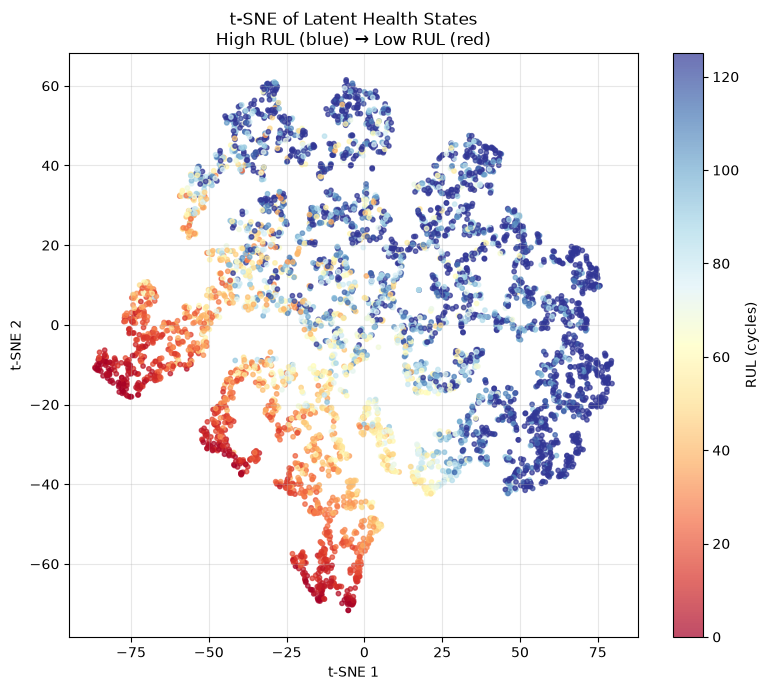

Saved → tsne_latent_space.png


In [14]:
# Cell 6 — Latent Space Visualization

model.eval()

all_latents  = []
all_rul_vals = []

BATCH = 512
train_X_tensor = torch.tensor(X_train, dtype=torch.float32)
train_y_tensor = torch.tensor(y_train, dtype=torch.float32)

with torch.no_grad():
    for start in range(0, len(train_X_tensor), BATCH):
        xb = train_X_tensor[start:start + BATCH].to(device)
        yb = train_y_tensor[start:start + BATCH]
        z = model.encode(xb)                      # (B, WINDOW, L)
        last_z = z[:, -1, :].cpu().numpy()        # (B, L)
        last_y = yb[:, -1].numpy()                # (B,)
        all_latents.append(last_z)
        all_rul_vals.append(last_y)

all_latents  = np.vstack(all_latents)
all_rul_vals = np.hstack(all_rul_vals)
print(f'Latent matrix: {all_latents.shape}')

scaler_tsne    = StandardScaler()
latents_normed = scaler_tsne.fit_transform(all_latents)

N_TSNE_MAX = 5000
if len(latents_normed) > N_TSNE_MAX:
    idx         = np.random.default_rng(42).choice(len(latents_normed), N_TSNE_MAX, replace=False)
    latents_sub = latents_normed[idx]
    rul_sub     = all_rul_vals[idx]
else:
    latents_sub = latents_normed
    rul_sub     = all_rul_vals

print(f'Running t-SNE on {len(latents_sub)} points...')
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)  # max_iter for sklearn >=1.2
embedding = tsne.fit_transform(latents_sub)

fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(embedding[:, 0], embedding[:, 1],
                c=rul_sub, cmap='RdYlBu', s=10, alpha=0.7, vmin=0, vmax=MAX_RUL)
plt.colorbar(sc, ax=ax, label='RUL (cycles)')
ax.set_title('t-SNE of Latent Health States\nHigh RUL (blue) → Low RUL (red)')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('tsne_latent_space.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved → tsne_latent_space.png')


In [15]:
# Cell 7 — Maintenance Schedule

N_MC       = 30
N_ROLLOUT  = 120  # look far enough ahead to find failure
FAIL_THRESH = 5.0  # RUL threshold to call 'failure imminent'

schedule = []  # list of dicts

for eng in test_engines:
    grp = test_df[test_df['engine'] == eng]
    sensors = grp[keep_sensors].values.astype(np.float32)
    T = len(sensors)

    # Seed window
    if T >= WINDOW:
        seed = sensors[-WINDOW:]
    else:
        pad = np.repeat(sensors[:1], WINDOW - T, axis=0)
        seed = np.vstack([pad, sensors])

    # MC Rollout
    _, rul_traj, rul_std = model.mc_rollout(seed, n_steps=N_ROLLOUT, n_samples=N_MC)
    model.eval()  # restore

    # Current RUL estimate = first step of rollout
    current_rul  = float(rul_traj[0])
    current_std  = float(rul_std[0])

    # Find first step where mean RUL crosses below FAIL_THRESH
    fail_steps = np.where(rul_traj <= FAIL_THRESH)[0]
    if len(fail_steps) > 0:
        estimated_failure_in = int(fail_steps[0])
    else:
        estimated_failure_in = N_ROLLOUT  # didn't fail within rollout horizon

    true_rul_val = float(rul_df.iloc[eng - 1]['rul_final'])

    schedule.append({
        'Engine': eng,
        'True RUL': round(true_rul_val, 1),
        'Pred RUL': round(current_rul, 1),
        'Uncertainty (±1σ)': round(current_std, 1),
        'Est. Failure in (steps)': estimated_failure_in,
        'Urgency': 'CRITICAL' if current_rul < 20 else ('HIGH' if current_rul < 50 else 'NORMAL')
    })

# Sort by predicted RUL (most urgent first)
schedule.sort(key=lambda x: x['Pred RUL'])

# Print table
print(f'{"Engine":>8} {"True RUL":>10} {"Pred RUL":>10} {"±1σ":>8} {"Fail In":>10} {"Urgency":>10}')
print('-' * 65)
for row in schedule[:20]:  # show top-20 most urgent
    print(
        f'{row["Engine"]:>8} '
        f'{row["True RUL"]:>10.1f} '
        f'{row["Pred RUL"]:>10.1f} '
        f'{row["Uncertainty (±1σ)"]  :>8.1f} '
        f'{row["Est. Failure in (steps)"]:>10d} '
        f'{row["Urgency"]:>10}'
    )

# Also as a DataFrame for cleaner display
schedule_df = pd.DataFrame(schedule)
print(f'\n--- Summary ---')
print(f'CRITICAL engines : {(schedule_df["Urgency"]=="CRITICAL").sum()}')
print(f'HIGH     engines : {(schedule_df["Urgency"]=="HIGH").sum()}')
print(f'NORMAL   engines : {(schedule_df["Urgency"]=="NORMAL").sum()}')
schedule_df.head(20)

  Engine   True RUL   Pred RUL      ±1σ    Fail In    Urgency
-----------------------------------------------------------------
      34        7.0        1.3      1.7          0   CRITICAL
      82        9.0        4.5      3.1          0   CRITICAL
      68        8.0        5.6      2.6          1   CRITICAL
      31        8.0        6.1      4.6          2   CRITICAL
      81        8.0        6.8      3.2          3   CRITICAL
      76       10.0       10.1      4.7          6   CRITICAL
      35       11.0       11.1      3.1          7   CRITICAL
      56       15.0       14.4      4.3        120   CRITICAL
      66       14.0       16.2      3.1         11   CRITICAL
      42       10.0       17.0      4.4        120   CRITICAL
      61       21.0       17.6      3.8         11   CRITICAL
      20       16.0       18.5      4.8         12   CRITICAL
      49       21.0       18.7      4.4         15   CRITICAL
      64       28.0       18.8      4.0         11   CRITICAL
    

,Engine,True RUL,Pred RUL,Uncertainty (±1σ),Est. Failure in (steps),Urgency
0,34,7.0,1.3,1.7,0,CRITICAL
1,82,9.0,4.5,3.1,0,CRITICAL
2,68,8.0,5.6,2.6,1,CRITICAL
3,31,8.0,6.1,4.6,2,CRITICAL
4,81,8.0,6.8,3.2,3,CRITICAL
5,76,10.0,10.1,4.7,6,CRITICAL
6,35,11.0,11.1,3.1,7,CRITICAL
7,56,15.0,14.4,4.3,120,CRITICAL
8,66,14.0,16.2,3.1,11,CRITICAL
9,42,10.0,17.0,4.4,120,CRITICAL


Fresh reference latent from 30 training engines.
Demo engine: 17  (True RUL = 50)
Factual failure in     : 50 cycles
Counterfactual failure : 55 cycles
Intervention benefit   : +5 cycles


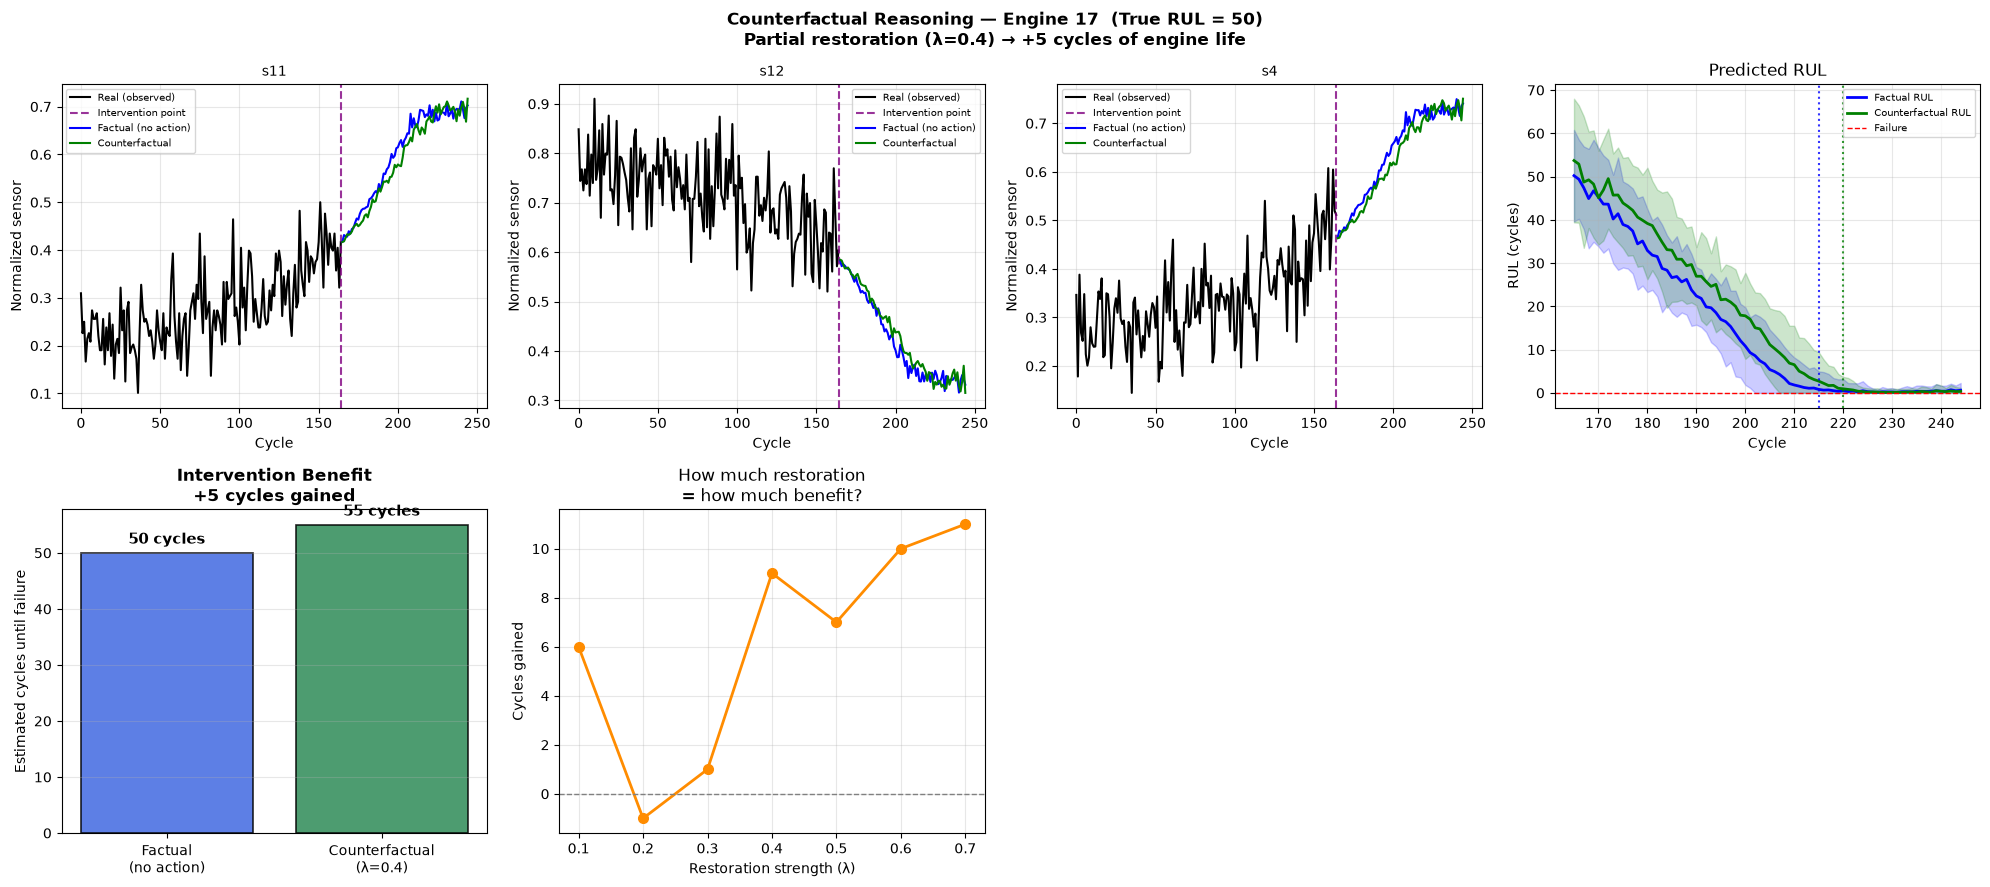

Saved → counterfactual_analysis.png


In [16]:
# Cell 8 — Counterfactual Reasoning: "What If We Had Intervened?"
#
# At a test engine's last observed cycle we simulate a maintenance action
# that partially restores its latent health state toward a fresh engine.
# Two rollouts then run in parallel:
#   Factual      — no action, degradation continues naturally
#   Counterfactual — engine state partially restored before rollout
# The gap between predicted failures = intervention benefit (cycles gained).

model.eval()

# ── 1. Compute "fresh engine" reference latent ─────────────────────────────
fresh_latents = []
for eng, grp in list(train_df.groupby('engine'))[:30]:
    s = grp[keep_sensors].values.astype(np.float32)
    if len(s) >= WINDOW:
        x = torch.tensor(s[:WINDOW][np.newaxis], dtype=torch.float32).to(device)
        with torch.no_grad():
            z_seq = model.encode(x)                          # (1, WINDOW, L)
            fresh_latents.append(z_seq[0, -1].cpu().numpy()) # (L,)

z_fresh_mean = np.mean(fresh_latents, axis=0)               # (L,)
print(f'Fresh reference latent from {len(fresh_latents)} training engines.')


# ── 2. Counterfactual rollout function ────────────────────────────────────
def counterfactual_rollout(engine_id, restoration_lambda=0.4, n_steps=80, n_samples=30):
    """
    restoration_lambda: how far we push the latent toward fresh health.
                        0 = no change, 1 = fully restored to fresh engine.
    """
    grp = test_df[test_df['engine'] == engine_id]
    sensors_raw = grp[keep_sensors].values.astype(np.float32)  # (T, N_S)
    cycles      = grp['cycle'].values                           # (T,)
    T = len(sensors_raw)

    # Seed window: last WINDOW observed cycles
    if T >= WINDOW:
        seed = sensors_raw[-WINDOW:].copy()
    else:
        pad  = np.repeat(sensors_raw[:1], WINDOW - T, axis=0)
        seed = np.vstack([pad, sensors_raw]).copy()

    # Encode seed → latent at last cycle
    seed_t = torch.tensor(seed[np.newaxis], dtype=torch.float32).to(device)
    with torch.no_grad():
        z_seq = model.encode(seed_t)               # (1, WINDOW, L)
        z_T   = z_seq[0, -1].cpu().numpy()         # (L,)

    # Blend toward fresh state
    z_CF  = (1 - restoration_lambda) * z_T + restoration_lambda * z_fresh_mean  # (L,)

    # Decode z_CF → restored sensor readings
    z_CF_t = torch.tensor(z_CF, dtype=torch.float32).reshape(1, 1, -1).to(device)
    with torch.no_grad():
        restored = model.decode(z_CF_t).squeeze(0).squeeze(0).cpu().numpy()  # (N_S,)
        restored = restored.clip(0.0, 1.0)

    # Counterfactual seed: identical history, last step replaced with restored sensors
    cf_seed         = seed.copy()
    cf_seed[-1]     = restored

    # Parallel rollouts
    s_fact, r_fact, r_fact_std = model.mc_rollout(seed,    n_steps, n_samples)
    s_cf,   r_cf,   r_cf_std   = model.mc_rollout(cf_seed, n_steps, n_samples)
    model.eval()

    # When does each trajectory first predict RUL ≤ 1?
    fact_fail = next((i for i, r in enumerate(r_fact) if r <= 1.0), n_steps)
    cf_fail   = next((i for i, r in enumerate(r_cf)   if r <= 1.0), n_steps)

    return dict(
        engine=engine_id, real_sensors=sensors_raw, cycles=cycles, seed=seed, cf_seed=cf_seed,
        s_fact=s_fact, r_fact=r_fact, r_fact_std=r_fact_std,
        s_cf=s_cf,     r_cf=r_cf,     r_cf_std=r_cf_std,
        fact_fail=fact_fail, cf_fail=cf_fail,
        extension=cf_fail - fact_fail,
        lam=restoration_lambda,
    )


# ── 3. Pick demo engine: true RUL between 25 and 55 ──────────────────────
candidates = [(e, r) for e, r in zip(test_engines, true_ruls) if 25 <= r <= 55]
demo_eng, demo_true_rul = candidates[0] if candidates else (test_engines[0], true_ruls[0])
print(f'Demo engine: {demo_eng}  (True RUL = {demo_true_rul:.0f})')

res = counterfactual_rollout(demo_eng, restoration_lambda=0.4, n_steps=80, n_samples=30)
print(f'Factual failure in     : {res["fact_fail"]} cycles')
print(f'Counterfactual failure : {res["cf_fail"]} cycles')
print(f'Intervention benefit   : +{res["extension"]} cycles')


# ── 4. Visualization ──────────────────────────────────────────────────────
top_s_idx   = np.argsort(train_df[keep_sensors].std().values)[::-1][:3]
top_s_names = [keep_sensors[i] for i in top_s_idx]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
fig.suptitle(
    f'Counterfactual Reasoning — Engine {demo_eng}  '
    f'(True RUL = {demo_true_rul:.0f})\n'
    f'Partial restoration (λ={res["lam"]}) → +{res["extension"]} cycles of engine life',
    fontsize=12, fontweight='bold'
)

real_t   = np.arange(len(res['cycles']))
future_t = np.arange(len(res['cycles']), len(res['cycles']) + len(res['r_fact']))

# Sensor subplots
for col, (s_idx, s_name) in enumerate(zip(top_s_idx, top_s_names)):
    ax = axes[col]
    ax.plot(real_t,   res['real_sensors'][:, s_idx], 'k-',  lw=1.5, label='Real (observed)')
    ax.axvline(real_t[-1], color='purple', ls='--', lw=1.5, alpha=0.8, label='Intervention point')
    ax.plot(future_t, res['s_fact'][:, s_idx], 'b-',  lw=1.5, label='Factual (no action)')
    ax.plot(future_t, res['s_cf']  [:, s_idx], 'g-',  lw=1.5, label='Counterfactual')
    ax.set_title(s_name, fontsize=10)
    ax.set_xlabel('Cycle')
    ax.set_ylabel('Normalized sensor')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

# RUL trajectories
ax = axes[3]
ax.plot(future_t, res['r_fact'], 'b-', lw=2, label='Factual RUL')
ax.fill_between(future_t,
                np.maximum(0, res['r_fact'] - 1.96 * res['r_fact_std']),
                res['r_fact'] + 1.96 * res['r_fact_std'],
                alpha=0.2, color='blue')
ax.plot(future_t, res['r_cf'],   'g-', lw=2, label='Counterfactual RUL')
ax.fill_between(future_t,
                np.maximum(0, res['r_cf'] - 1.96 * res['r_cf_std']),
                res['r_cf'] + 1.96 * res['r_cf_std'],
                alpha=0.2, color='green')
ax.axhline(0, color='red', ls='--', lw=1, label='Failure')
if res['fact_fail'] < len(future_t):
    ax.axvline(future_t[res['fact_fail']], color='blue',  ls=':', lw=1.5, alpha=0.8)
if res['cf_fail'] < len(future_t):
    ax.axvline(future_t[res['cf_fail']],  color='green', ls=':', lw=1.5, alpha=0.8)
ax.set_title('Predicted RUL')
ax.set_xlabel('Cycle')
ax.set_ylabel('RUL (cycles)')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

# Benefit bar chart
ax = axes[4]
bars = ax.bar(
    ['Factual\n(no action)', f'Counterfactual\n(λ={res["lam"]})'],
    [res['fact_fail'], res['cf_fail']],
    color=['royalblue', 'seagreen'], alpha=0.85, edgecolor='black', linewidth=1.2
)
ax.bar_label(bars, fmt='%d cycles', padding=4, fontsize=11, fontweight='bold')
ax.set_ylabel('Estimated cycles until failure')
ax.set_title(f'Intervention Benefit\n+{res["extension"]} cycles gained', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# Benefit vs restoration lambda sweep
ax = axes[5]
lambdas   = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
benefits  = []
for lam in lambdas:
    r_sweep = counterfactual_rollout(demo_eng, restoration_lambda=lam, n_steps=80, n_samples=15)
    benefits.append(r_sweep['extension'])
    model.eval()

ax.plot(lambdas, benefits, 'o-', color='darkorange', lw=2, ms=7)
ax.set_xlabel('Restoration strength (λ)')
ax.set_ylabel('Cycles gained')
ax.set_title('How much restoration\n= how much benefit?')
ax.grid(True, alpha=0.3)
ax.axhline(0, color='gray', ls='--', lw=1)

for i in range(6, 8):
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('counterfactual_analysis.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → counterfactual_analysis.png')
